In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import os

print("Files available:", os.listdir("/content"))

# Clean file path pointing directly to the root /content folder
df = pd.read_csv("/content/Player Per Game.csv")

print("\nDataset loaded successfully!")
print("Dimensions:", df.shape)
display(df.head())

Files available: ['.config', 'Player Per Game.csv', 'sample_data']

Dataset loaded successfully!
Dimensions: (33339, 32)


,season,lg,player,player_id,age,team,pos,g,gs,mp_per_game,...,ft_percent,orb_per_game,drb_per_game,trb_per_game,ast_per_game,stl_per_game,blk_per_game,tov_per_game,pf_per_game,pts_per_game
0,2026,NBA,Precious Achiuwa,achiupr01,26.0,SAC,C,73,57.0,23.9,...,0.554,2.4,4.3,6.7,1.4,0.9,0.7,0.9,1.7,10.1
1,2026,NBA,Steven Adams,adamsst01,32.0,HOU,C,32,11.0,22.8,...,0.580,4.5,4.1,8.6,1.5,0.7,0.6,1.1,1.7,5.8
2,2026,NBA,Bam Adebayo,adebaba01,28.0,MIA,C,73,73.0,32.4,...,0.778,2.0,8.0,10.0,3.2,1.2,0.7,1.6,1.7,20.1
3,2026,NBA,Ochai Agbaji,agbajoc01,25.0,2TM,SG,62,13.0,15.7,...,0.837,0.7,1.5,2.3,0.8,0.4,0.3,0.5,1.5,5.1
4,2026,NBA,Ochai Agbaji,agbajoc01,25.0,TOR,SG,42,13.0,15.5,...,0.862,0.8,1.5,2.3,0.7,0.4,0.3,0.5,1.8,4.3


In [8]:

# Filter to NBA players in the 2025–26 season
nba = df[
    (df["lg"] == "NBA") &
    (df["season"] == 2026)
].copy()

# Exclude combined-team rows (e.g., 2TM)
nba = nba[~nba["team"].str.contains("TM", na=False)].copy()

# Keep players with at least 50 games played
qualified = nba[nba["g"] >= 50].copy()

# Display the top 10 scorers
top_scorers = qualified.sort_values(
    "pts_per_game", ascending=False
).head(10)

display(
    top_scorers[
        ["player", "team", "g", "pts_per_game", "e_fg_percent"]
    ]
)


,player,team,g,pts_per_game,e_fg_percent
164,Luka Dončić,LAL,64,33.5,0.563
214,Shai Gilgeous-Alexander,OKC,68,31.1,0.597
177,Anthony Edwards,MIN,61,28.8,0.572
82,Jaylen Brown,BOS,71,28.7,0.522
420,Tyrese Maxey,PHI,70,28.3,0.536
459,Donovan Mitchell,CLE,70,27.9,0.563
388,Kawhi Leonard,LAC,65,27.9,0.573
326,Nikola Jokić,DEN,65,27.7,0.618
67,Devin Booker,PHO,64,26.1,0.507
172,Kevin Durant,HOU,78,26.0,0.588


Scoring-efficiency correlation: 0.001


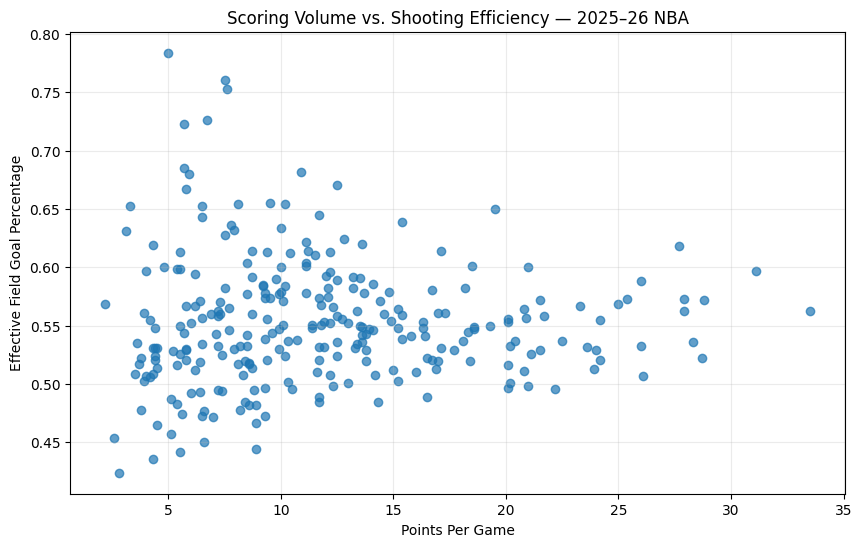

In [9]:

# Calculate correlation across all qualified players
correlation = qualified["pts_per_game"].corr(
    qualified["e_fg_percent"]
)

print(f"Scoring-efficiency correlation: {correlation:.3f}")

# Visualize every qualified player
plt.figure(figsize=(10, 6))

plt.scatter(
    qualified["pts_per_game"],
    qualified["e_fg_percent"],
    alpha=0.7
)

plt.xlabel("Points Per Game")
plt.ylabel("Effective Field Goal Percentage")
plt.title("Scoring Volume vs. Shooting Efficiency — 2025–26 NBA")
plt.grid(alpha=0.25)
plt.show()


In [11]:

# Focus on players who score at least 20 points per game
high_scorers = qualified[
    qualified["pts_per_game"] >= 20
].copy()

# Sort these players by effective field goal percentage
most_efficient = high_scorers.sort_values(
    "e_fg_percent", ascending=False
)

display(
    most_efficient[
        ["player", "team", "g", "pts_per_game", "e_fg_percent"]
    ].head(15)
)


,player,team,g,pts_per_game,e_fg_percent
326,Nikola Jokić,DEN,65,27.7,0.618
712,Zion Williamson,NOP,62,21.0,0.600
214,Shai Gilgeous-Alexander,OKC,68,31.1,0.597
172,Kevin Durant,HOU,78,26.0,0.588
388,Kawhi Leonard,LAC,65,27.9,0.573
471,Jamal Murray,DEN,75,25.4,0.573
468,Trey Murphy III,NOP,66,21.5,0.572
177,Anthony Edwards,MIN,61,28.8,0.572
685,Victor Wembanyama,SAS,64,25.0,0.569
540,Austin Reaves,LAL,51,23.3,0.567


,player_count,avg_points,avg_efg,median_efg
scoring_group,,,,
20+ PPG,37,23.832,0.545,0.537
Below 20 PPG,232,9.877,0.555,0.548


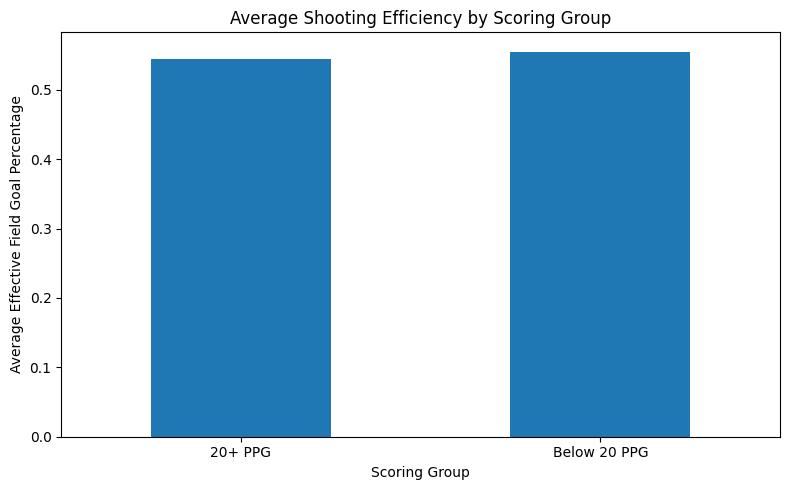

In [12]:

# Divide qualified players into two groups
qualified["scoring_group"] = qualified["pts_per_game"].apply(
    lambda points: "20+ PPG" if points >= 20 else "Below 20 PPG"
)

# Compare the groups
comparison = qualified.groupby("scoring_group").agg(
    player_count=("player", "count"),
    avg_points=("pts_per_game", "mean"),
    avg_efg=("e_fg_percent", "mean"),
    median_efg=("e_fg_percent", "median")
).round(3)

display(comparison)

# Visualize average shooting efficiency
comparison["avg_efg"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Shooting Efficiency by Scoring Group",
    ylabel="Average Effective Field Goal Percentage",
    xlabel="Scoring Group",
    rot=0
)

plt.tight_layout()
plt.show()


Project Notes: Based on NBA stats for the 2025-26 season, I compared players who played at least 50 games and then separated them into two groups where one averaged more than 20PPG and one that is less than 20PPG. Among the 37 players in the higher scoring group, the average effective field goal percentage was 54.5% while the 232 players in the lower scoring group averaged 55.5%. This observation suggests that higher scoring volume does not correlate to greater shooting efficiency. Further analysis is needed to find out if this difference is statistically meaningful and factors such as shot selection affects this data.

In [13]:

from scipy.stats import ttest_ind

high = qualified.loc[
    qualified["pts_per_game"] >= 20, "e_fg_percent"
].dropna()

low = qualified.loc[
    qualified["pts_per_game"] < 20, "e_fg_percent"
].dropna()

# Welch's t-test does not assume equal group variances
t_stat, p_value = ttest_ind(
    high, low, equal_var=False
)

print("High scorers:")
print("Mean eFG%:", round(high.mean() * 100, 2))
print("Standard deviation:", round(high.std() * 100, 2))

print("\nLower scorers:")
print("Mean eFG%:", round(low.mean() * 100, 2))
print("Standard deviation:", round(low.std() * 100, 2))

print("\nWelch's t-test")
print("t-statistic:", round(t_stat, 3))
print("p-value:", round(p_value, 4))


High scorers:
Mean eFG%: 54.52
Standard deviation: 3.1

Lower scorers:
Mean eFG%: 55.46
Standard deviation: 5.76

Welch's t-test
t-statistic: -1.484
p-value: 0.1415


Current benchmark finding: I analyzed 269 NBA players who played 50+ games during the 2025-26 season separating players who scored 20+ points (37 players) and under 20 points (232 players). Higher scorers scored a mean percentage of 54.52% while the lower scorers had a mean percentage of 55.46%. The two sample t-test got us a p-value of 0.1415 so the statistic did not end up being significant at the 0.05 level. As a result, this doesnt provide sufficient evidence to prove a significant different between the two scoring groups.

In [2]:
import pandas as pd
from scipy.stats import linregress

# Ensure the dataset is loaded and qualified players are defined
try:
    # If already in memory, use it
    _ = qualified
except NameError:
    # Otherwise, rebuild qualified players from the source CSV
    df = pd.read_csv("/content/Player Per Game.csv")
    nba = df[(df["lg"] == "NBA") & (df["season"] == 2026)].copy()
    nba = nba[~nba["team"].str.contains("TM", na=False)].copy()
    qualified = nba[nba["g"] >= 50].copy()

# Fit a linear model across all qualified players
model = linregress(
    qualified["pts_per_game"],
    qualified["e_fg_percent"]
)

# Predict efficiency based on scoring average
qualified["predicted_efg"] = (
    model.intercept +
    model.slope * qualified["pts_per_game"]
)

# Calculate actual minus predicted efficiency
qualified["efg_residual"] = (
    qualified["e_fg_percent"] -
    qualified["predicted_efg"]
)

# Rank players who score at least 20 PPG
high_scorers = qualified[
    qualified["pts_per_game"] >= 20
].copy()

overperformers = high_scorers.sort_values(
    "efg_residual", ascending=False
)

display(
    overperformers[
        ["player", "team", "pts_per_game",
         "e_fg_percent", "predicted_efg", "efg_residual"]
    ].head(10).round(3)
)

,player,team,pts_per_game,e_fg_percent,predicted_efg,efg_residual
326,Nikola Jokić,DEN,27.7,0.618,0.553,0.065
712,Zion Williamson,NOP,21.0,0.600,0.553,0.047
214,Shai Gilgeous-Alexander,OKC,31.1,0.597,0.554,0.043
172,Kevin Durant,HOU,26.0,0.588,0.553,0.035
471,Jamal Murray,DEN,25.4,0.573,0.553,0.020
388,Kawhi Leonard,LAC,27.9,0.573,0.553,0.020
468,Trey Murphy III,NOP,21.5,0.572,0.553,0.019
177,Anthony Edwards,MIN,28.8,0.572,0.553,0.019
685,Victor Wembanyama,SAS,25.0,0.569,0.553,0.016
540,Austin Reaves,LAL,23.3,0.567,0.553,0.014


In [3]:

from scipy.stats import linregress
import numpy as np

model = linregress(
    qualified["pts_per_game"],
    qualified["e_fg_percent"]
)

print(f"Slope: {model.slope:.5f}")
print(f"R-squared: {model.rvalue**2:.5f}")
print(f"Correlation: {model.rvalue:.5f}")
print(f"P-value: {model.pvalue:.5f}")


Slope: 0.00001
R-squared: 0.00000
Correlation: 0.00113
P-value: 0.98524


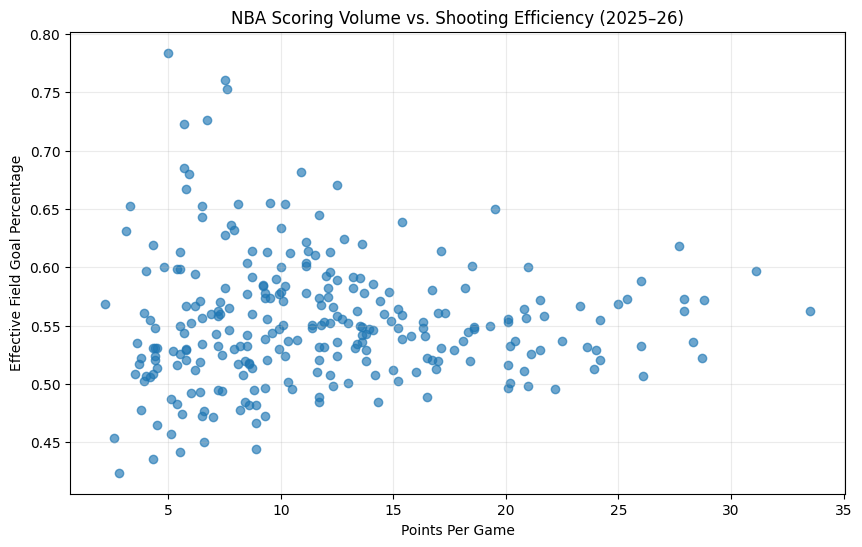

In [4]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    qualified["pts_per_game"],
    qualified["e_fg_percent"],
    alpha=0.65
)

plt.xlabel("Points Per Game")
plt.ylabel("Effective Field Goal Percentage")
plt.title("NBA Scoring Volume vs. Shooting Efficiency (2025–26)")
plt.grid(alpha=0.25)

plt.show()


In [5]:

# Focus on players averaging at least 20 points per game
high_scorers = qualified[
    qualified["pts_per_game"] >= 20
].copy()

# Rank by shooting efficiency
high_scorers = high_scorers.sort_values(
    "e_fg_percent", ascending=False
)

display(
    high_scorers[
        ["player", "team", "pos", "g",
         "pts_per_game", "e_fg_percent"]
    ].head(15).round(3)
)


,player,team,pos,g,pts_per_game,e_fg_percent
326,Nikola Jokić,DEN,C,65,27.7,0.618
712,Zion Williamson,NOP,PF,62,21.0,0.600
214,Shai Gilgeous-Alexander,OKC,PG,68,31.1,0.597
172,Kevin Durant,HOU,SF,78,26.0,0.588
388,Kawhi Leonard,LAC,SF,65,27.9,0.573
471,Jamal Murray,DEN,PG,75,25.4,0.573
468,Trey Murphy III,NOP,SF,66,21.5,0.572
177,Anthony Edwards,MIN,SG,61,28.8,0.572
685,Victor Wembanyama,SAS,C,64,25.0,0.569
540,Austin Reaves,LAL,SG,51,23.3,0.567


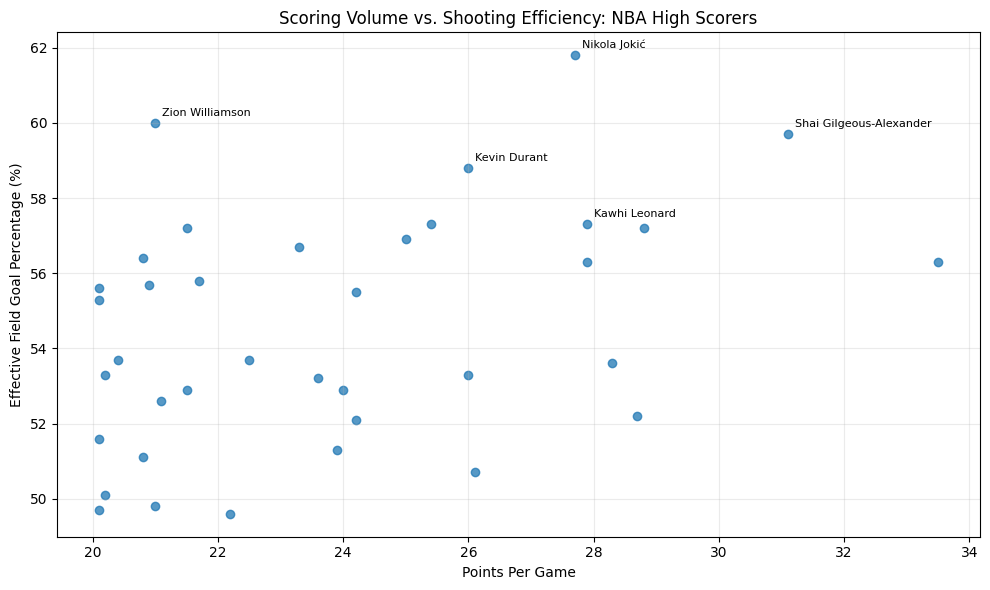

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    high_scorers["pts_per_game"],
    high_scorers["e_fg_percent"] * 100,
    alpha=0.75
)

# Label the five most efficient players
top_five = high_scorers.head(5)

for _, row in top_five.iterrows():
    plt.annotate(
        row["player"],
        (row["pts_per_game"], row["e_fg_percent"] * 100),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Points Per Game")
plt.ylabel("Effective Field Goal Percentage (%)")
plt.title("Scoring Volume vs. Shooting Efficiency: NBA High Scorers")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [7]:

# Compare average shooting efficiency by position
position_stats = (
    qualified.groupby("pos")
    .agg(
        player_count=("player", "count"),
        avg_ppg=("pts_per_game", "mean"),
        avg_efg=("e_fg_percent", "mean"),
        median_efg=("e_fg_percent", "median")
    )
    .sort_values("avg_efg", ascending=False)
)

position_stats["avg_efg"] *= 100
position_stats["median_efg"] *= 100

display(position_stats.round(2))


,player_count,avg_ppg,avg_efg,median_efg
pos,,,,
C,47,10.72,60.95,60.00
PF,54,10.87,55.31,54.65
SF,56,12.99,54.67,54.65
SG,68,11.04,53.70,53.60
PG,44,13.71,52.71,53.05


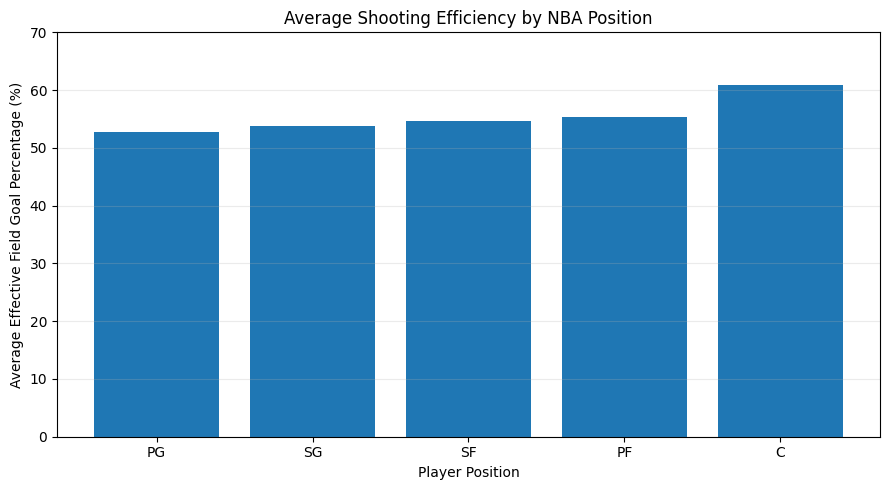

In [8]:

import matplotlib.pyplot as plt

plot_data = position_stats.sort_values("avg_efg")

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data.index,
    plot_data["avg_efg"]
)

plt.xlabel("Player Position")
plt.ylabel("Average Effective Field Goal Percentage (%)")
plt.title("Average Shooting Efficiency by NBA Position")
plt.ylim(0, 70)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


In [9]:

from scipy.stats import f_oneway

# Collect eFG% values for each position
positions = ["C", "PF", "SF", "SG", "PG"]

groups = [
    qualified.loc[qualified["pos"] == pos, "e_fg_percent"].dropna()
    for pos in positions
]

# Run one-way ANOVA
f_stat, p_value = f_oneway(*groups)

print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("The mean eFG% differs significantly across at least some positions.")
else:
    print("Insufficient evidence of a difference in mean eFG% across positions.")


F-statistic: 21.6508
P-value: 0.000000
The mean eFG% differs significantly across at least some positions.


In [10]:

from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=qualified["e_fg_percent"].dropna(),
    groups=qualified.loc[
        qualified["e_fg_percent"].notna(), "pos"
    ],
    alpha=0.05
)

print(tukey)


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     C     PF  -0.0564    0.0 -0.0826 -0.0301   True
     C     PG  -0.0823    0.0 -0.1099 -0.0547   True
     C     SF  -0.0628    0.0 -0.0888 -0.0367   True
     C     SG  -0.0724    0.0 -0.0974 -0.0475   True
    PF     PG   -0.026 0.0613 -0.0527  0.0008  False
    PF     SF  -0.0064 0.9559 -0.0315  0.0187  False
    PF     SG  -0.0161  0.353 -0.0401  0.0079  False
    PG     SF   0.0196 0.2562  -0.007  0.0461  False
    PG     SG   0.0099 0.8224 -0.0156  0.0354  False
    SF     SG  -0.0097 0.7978 -0.0334  0.0141  False
----------------------------------------------------


Main conclusion so far: By doing a one way ANOVA test, it found statistically significant differences in mean field goal pct across the 5 nba positions (F=21.61, p<0.001). Also, the tukey post hoc comparisons showed that centers have a higher mean eFG% than power forwards, small forwards, shooting guards, and point guards. The other 4 positions did not show any statistical significances. These findings suggest that the shooting efficiency in this dataset are primarily driven by centers higher eFG%. But because this is only observational, this does not mean that playing center would cause you higher shooting efficiency.

In [11]:

# Calculate eta-squared for the one-way ANOVA
overall_mean = qualified["e_fg_percent"].mean()

ss_between = sum(
    len(group) * (group.mean() - overall_mean) ** 2
    for group in groups
)

ss_total = (
    (qualified["e_fg_percent"] - overall_mean) ** 2
).sum()

eta_squared = ss_between / ss_total

print(f"Eta-squared: {eta_squared:.4f}")
print(f"Variation associated with position: {eta_squared * 100:.2f}%")


Eta-squared: 0.2470
Variation associated with position: 24.70%
